# Delta Cards pipeline demo

Set one image path, run the pipeline, and inspect the result.

In [1]:
import asyncio
import glob
import os
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

# Ensure repository root is on sys.path
ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from delta_cards.recognition.pipeline import CardRecognitionPipeline
from delta_cards.recognition.vector_index import USearchCardIndex


## Select a card image

Use a local image path or an `https://` URL.

In [2]:
IMAGE_SOURCE = ROOT / "data/test_image/45a324ea.webp"
IMAGE_SOURCE = str(IMAGE_SOURCE)
IMAGE_SOURCE


'/home/javij/delta-cards/data/test_image/45a324ea.webp'

## Run the pipeline

In [3]:
# Initialize pipeline with vector index and SQLite metadata
pipeline = CardRecognitionPipeline(
    vector_index=USearchCardIndex(
        index_path=str(ROOT / "data/pokemon_cards.usearch"),
        meta_path=str(ROOT / "data/pokemon_cards_meta.sqlite"),
        view_only=True,
    )
)

# Run recognition (Jupyter natively supports top-level await)
result = await pipeline.process_card_listing(IMAGE_SOURCE)

# Print execution summary
print(f"Status:            {result.get('status')}")
print(f"Extraction Method: {result.get('extraction_method')}")
print(f"Isolation Status:  {result.get('isolation_status')}")
print(f"Confidence:        {result.get('confidence', 0.0):.1%}")

if result.get("verified_card"):
    card = result["verified_card"]
    print("\n--- MATCHED CARD ---")
    print(f"Name:   {card.get('name')}")
    print(f"ID:     {card.get('id')}")
    print(f"Lang:   {card.get('lang')}")
    print(f"Set:    {card.get('set', {}).get('name')} ({card.get('set', {}).get('id')})")
    print(f"Local#: {card.get('localId')}")
    if card.get("rarity"):
        print(f"Rarity: {card.get('rarity')}")
    if card.get("hp"):
        print(f"HP:     {card.get('hp')}")

if result.get("cardmarket"):
    print(f"\nCardmarket: {result['cardmarket'].get('url')}")

print(f"\nElapsed time: {result.get('profiling', {}).get('total_s', 0):.2f}s")


Loading /home/javij/delta-cards/models/riftbound_regions.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.30.0 with CPUExecutionProvider
Status:            rejected
Extraction Method: rejected
Isolation Status:  isolated
Confidence:        45.6%

Elapsed time: 7.50s


## Display results

### 1. Original image and BBox detection

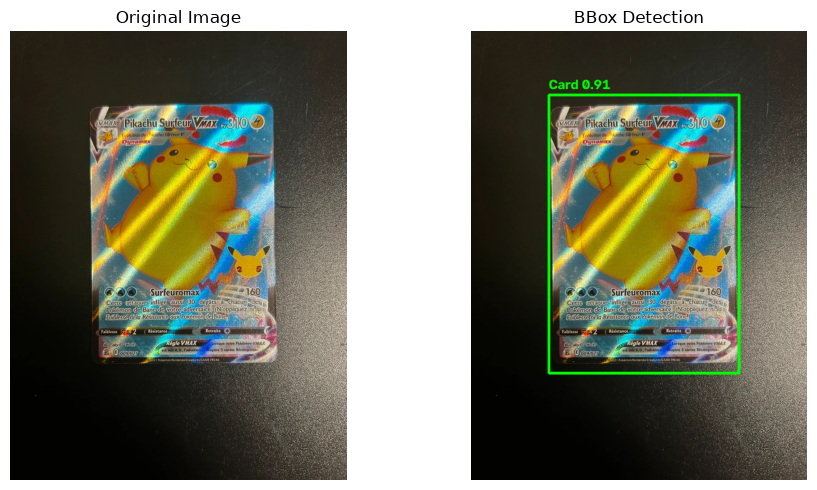

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# Original image (handles paths, URLs, and branch compatibility)
if hasattr(pipeline, "isolator") and hasattr(pipeline.isolator, "load_image"):
    orig_img = pipeline.isolator.load_image(IMAGE_SOURCE)
elif hasattr(pipeline, "detector") and hasattr(pipeline.detector, "_load_image"):
    orig_img = pipeline.detector._load_image(IMAGE_SOURCE)
else:
    orig_img = cv2.imread(str(IMAGE_SOURCE))

if orig_img is not None:
    ax1.imshow(cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB))
ax1.set_title("Original Image")
ax1.axis("off")

# BBox Detection / Cropped Card
annotated = result.get("debug_trace", {}).get("annotated_image")
if annotated is not None:
    ax2.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
    ax2.set_title("BBox Detection")
else:
    card_img = result.get("debug_trace", {}).get("card_image")
    if card_img is not None:
        ax2.imshow(cv2.cvtColor(card_img, cv2.COLOR_BGR2RGB))
        ax2.set_title(f"Cropped Card ({result.get('isolation_status', 'fallback')})")
    else:
        ax2.text(0.5, 0.5, "No detection available", ha="center", va="center")
        ax2.set_title("BBox Detection")
ax2.axis("off")

plt.tight_layout()
plt.show()

### 2. Image candidates from USearch (3x5)

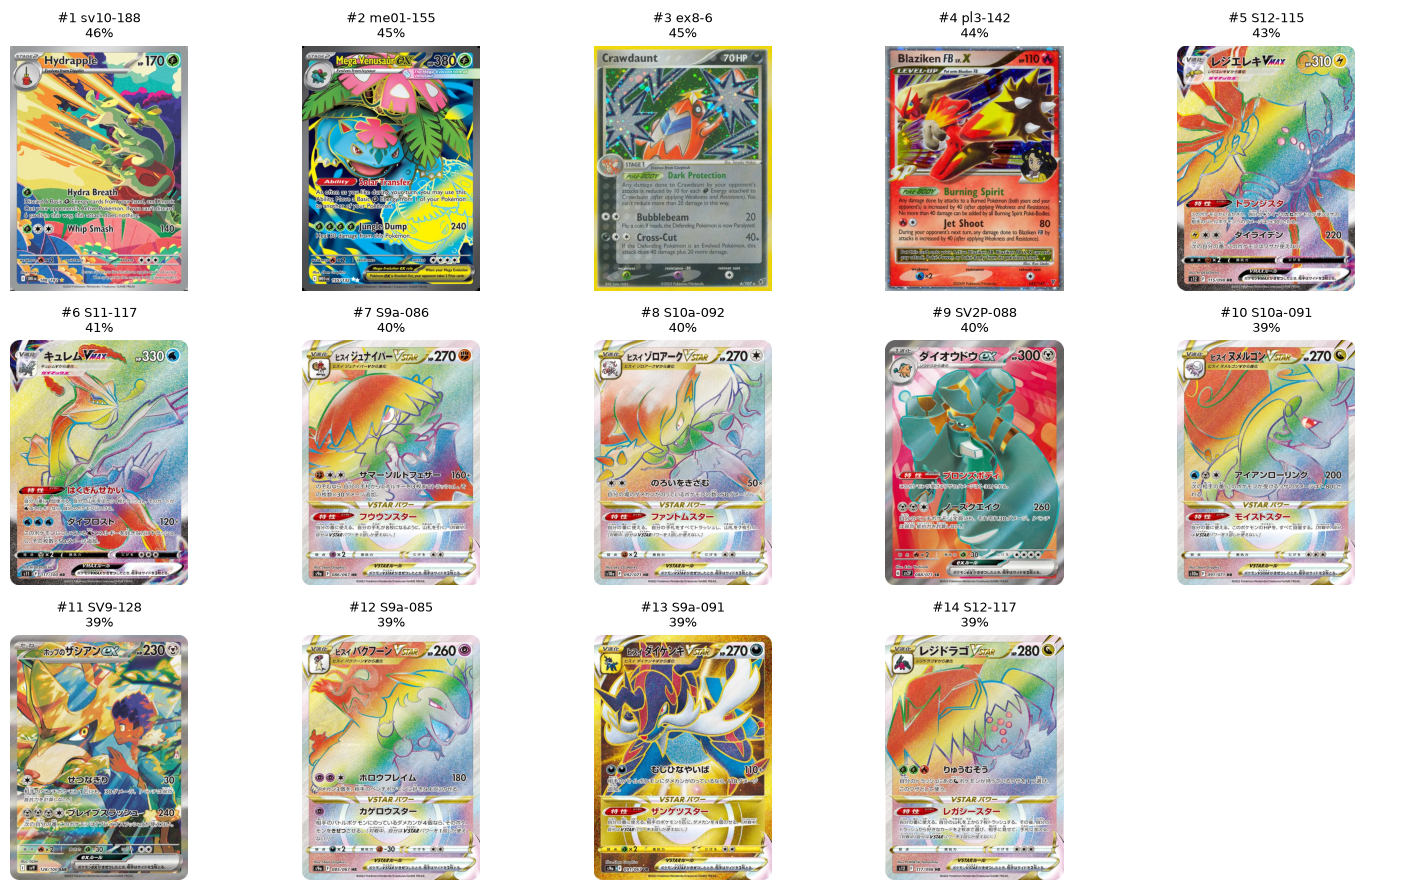

In [5]:
candidates = result.get("debug_trace", {}).get("candidates", [])
detected_lang = result.get("query_ocr", {}).get("detected_language") or result.get("debug_trace", {}).get("winner_language") or "es"
fig, axes = plt.subplots(3, 5, figsize=(15, 9))

for i, ax in enumerate(axes.flat):
    if i < len(candidates):
        cand = candidates[i]
        tcgdex_id = cand.get("tcgdex_id") or "unknown"
        score = cand.get("combined_score", cand.get("similarity", 0.0))

        # Try resolving candidate image path via pipeline cache or glob fallback
        img_path = None
        if hasattr(pipeline, "ocr_cache") and hasattr(pipeline.ocr_cache, "resolve_candidate_image_path"):
            img_path = pipeline.ocr_cache.resolve_candidate_image_path(cand, detected_lang) or                        pipeline.ocr_cache.resolve_candidate_image_path(cand, "en")

        if not img_path:
            clean_id = tcgdex_id.replace("-", "_")
            files = glob.glob(f"data/images_cache/*/{clean_id}.webp") or glob.glob(f"data/images_cache/*/{tcgdex_id}.webp")
            if files:
                img_path = files[0]

        img = cv2.imread(img_path) if img_path else None
        if img is not None:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.text(0.5, 0.5, "(no cached image)", ha="center", va="center", fontsize=8)

        ax.set_title(f"#{cand.get('rank', i+1)} {tcgdex_id}\n{score:.0%}", fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

### 3. OCR text from image and candidates with scores

In [6]:
print("--- QUERY OCR TEXT ---")
query_text = result.get("query_ocr", {}).get("full_text", "")
print(query_text if query_text else "(No OCR text detected)")

print("\n--- CANDIDATES OCR TEXT & SCORES ---")
candidates = result.get("debug_trace", {}).get("candidates", [])
for cand in candidates:
    rank = cand.get("rank", "?")
    tcgdex_id = cand.get("tcgdex_id", "unknown")
    score = cand.get("combined_score", cand.get("similarity", 0.0))
    full_text = cand.get("full_text", "")
    if not full_text and hasattr(pipeline.ocr_cache, "get_cached_ocr"):
        cached = pipeline.ocr_cache.get_cached_ocr(tcgdex_id, cand.get("lang", "en"))
        if cached:
            full_text = cached.get("full_text", "")
    elif not full_text and hasattr(pipeline.ocr_cache, "get_cached_text"):
        full_text = pipeline.ocr_cache.get_cached_text(tcgdex_id, cand.get("lang", "en")) or ""

    print(f"[{rank}] {tcgdex_id} (Score: {score:.0%})")
    if full_text:
        print(f"    {full_text.strip()}\n")

--- QUERY OCR TEXT ---
(No OCR text detected)

--- CANDIDATES OCR TEXT & SCORES ---
[1] sv10-188 (Score: 46%)
    SLAGEE Hydrapple 170 キ HP Evolves from Dipplin Hydra Breath Discard 6 Basie e Energy cards from your hand, and Knock. Out your oppenent's Acuive Pokemon. If you cant discard A cards in this way, this attack does nothing. Whip Smash 140 Weakness ×2 resistance retreat Illus. Jerky Seven syrpens live insidleanapplemadeof syrup. DRIE 188/182 02025POkGmO円fNintNdCGHtUrGSGAMEFREAK

[2] me01-155 (Score: 45%)
    Mega-Venusaur! 83801 Evoluciona de lvysaur Laforma megaevoluconada devenusaur Habilidad Traspaso Solar Todas las veces que qufieras durante tu turno, puedes usar esta habilldad. . Mueve I Energia Basica de uno de tus. Pokémon a otro de tus Pokemon. Descarga Selvatica 240 Cura 3o puntos de dano a este Pokémon. DebilidadC ×2 Resistenca Retirada 本に Reglg Megaavolucibnex Jus. Sban Graphics CuandotuPokemonex HEGS Hegaevalucion quedaFucrade Combate, turival coge 3 cartas dePremio

### 4. LLM verification output

In [7]:
from types import SimpleNamespace
from delta_cards.recognition.llm_verifier import get_llm_verifier

candidates = result.get("debug_trace", {}).get("candidates", [])

if candidates:
    top_cand = candidates[0]
    cand_text = top_cand.get("full_text", "")
    if not cand_text and hasattr(pipeline.ocr_cache, "get_cached_ocr"):
        cached = pipeline.ocr_cache.get_cached_ocr(top_cand.get("tcgdex_id"), top_cand.get("lang", "es"))
        if cached:
            cand_text = cached.get("full_text", "")
    elif not cand_text and hasattr(pipeline.ocr_cache, "get_cached_text"):
        cand_text = pipeline.ocr_cache.get_cached_text(top_cand.get("tcgdex_id"), top_cand.get("lang", "es")) or ""

    offer = SimpleNamespace(
        title="",
        description="",
        tcgdex_id=top_cand.get("tcgdex_id", ""),
        language=top_cand.get("lang", "es"),
        _query_ocr=result.get("query_ocr", {}),
        _candidate_ocr={"full_text": cand_text},
    )

    verifier = get_llm_verifier()
    llm_res = verifier.verify_match(
        offer=offer,
        query_ocr=result.get("query_ocr", {}),
        candidate_ocr={"full_text": cand_text},
        tcgdex_card=top_cand.get("card") or top_cand,
    )

    print(f"Candidate:  {top_cand.get('tcgdex_id')}")
    print(f"Verified:   {llm_res.is_verified}")
    print(f"Verdict:    {llm_res.verdict_summary}")
    print(f"Confidence: {llm_res.confidence_score:.0f}%")
    print(f"Inference:  {llm_res.inference_time_s:.2f}s")
    print(f"Raw Output: {llm_res.raw_response}")
else:
    llm_res = None
    print("No candidates available for verification.")

Candidate:  sv10-188
Verified:   False
Verdict:    Veto IA: Nombre no coincide, Veredicto global rechazado
Confidence: 25%
Inference:  8.08s
Raw Output: 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0


In [8]:
llm_res


LLMVerificationResult(is_verified=False, confidence_score=25.0, confirmed_count=16, total_questions=20, checks={'q01_pokemon_name_match': False, 'q02_stage_evolution_match': True, 'q03_hp_alignment': True, 'q04_pokemon_type_consistent': True, 'q05_collector_number_match': False, 'q06_total_card_count_match': True, 'q07_promo_code_alignment': True, 'q08_set_expansion_consistent': True, 'q09_primary_attack_name': True, 'q10_attack_damage_match': True, 'q11_secondary_attack_or_ability': True, 'q12_energy_rules_or_retreat': True, 'q13_ocr_text_subset_valid': False, 'q14_card_mechanic_badge': True, 'q15_rarity_visual_indicator': True, 'q16_no_contradictory_pokemon': True, 'q17_wallapop_title_mentions_card': True, 'q18_wallapop_description_consistent': True, 'q19_single_card_not_bulk_lot': True, 'q20_overall_verdict_genuine_match': False}, questions_detail=[QuestionCheck(id='q01_pokemon_name_match', question='Pokemon name in photo OCR matches TCGdex candidate name', question_es='¿El nombre d

## Test an image outside the database

Set an arbitrary local path or public image URL, then rerun the pipeline and display cells above.

In [9]:
# Example: a local image or any public card-image URL.
# IMAGE_SOURCE = ROOT / "data/evaluation_set/images/sample_015_spanish_xy6-075.jpg"
# IMAGE_SOURCE = "https://images.pokemontcg.io/swsh7/192_hires.png"
#
# Rerun the "Run the pipeline" and display cells above.
